# M5 Retail Demand Forecasting — Notebook 2: Feature Engineering

**This notebook:** turn the EDA findings into model-ready features, **prove that the features contain no leakage**, define time-based validation folds, and measure the value of each feature family.

| | |
|---|---|
| **Inputs** | `m5_sample_long.parquet` (Notebook 1) |
| **Outputs** | `features_h7/h14/h28.parquet`, `feature_config.json` |
| **Libraries** | pandas, numpy, matplotlib, lightgbm |

**How the EDA findings map to features**

| EDA finding | Feature decision |
|---|---|
| Missing price implies the item was not on sale (structural zeros) | those rows are `NaN`, not zero; training only on available rows |
| 56% of available rows are still zero (intermittent) | intermittency features; Tweedie loss |
| Weekend sales ~20% above average | `dow`, `is_weekend`, same-weekday lags |
| Sales ~0 on 25 December | `is_christmas` flag |
| SNAP lift mainly in FOODS | `snap` feature |
| Prices change in only ~1% of weeks | price features, with their value checked by ablation |

---
## 0. Forecast origin and horizon

- **Forecast origin (T):** the day on which the forecast is produced. Only data up to T is known.
- **Horizon (h):** how many days ahead we forecast.
- **Target date (t):** the day being predicted, `t = T + h`.

```
 ...... known past ......  T ........ unknown ........ t = T + h
                           ^                           ^
                  forecast made here           value to predict
```

Every row of the model table is a target date `t`. Its features may only use information available at `T = t - h`.

**Direct approach.** For `h = 28`, yesterday's sales (`lag_1`) are not available when the forecast is made 28 days earlier. Therefore **every sales-based feature is shifted by at least `h` days**:
- `h = 28`: lags 28, 35, 42, 49
- `h = 7`: lags 7, 14, 21, 28

Lags are multiples of 7 so that the weekday is preserved (weekly seasonality was strong in the EDA).

---
## 1. Setup and data loading

The cleaned long table from Notebook 1 is loaded. The first cell locates the file automatically (local folder or Kaggle input).

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ---------- Locate the input file ----------
FNAME = "m5_sample_long.parquet"
found = []
for root in [Path(".")] + ([Path("..")] if not Path("data").exists() else []) + [Path("/kaggle/working"), Path("/kaggle/input")]:
    if root.exists():
        found += list(root.rglob(FNAME))
if not found:
    raise FileNotFoundError(
        f"{FNAME} not found. Run Notebook 1 (Section 12) first, or add its output as an input on Kaggle."
    )
IN_PATH = found[0]
print("Input:", IN_PATH)

# ---------- Output folder ----------
OUT = Path("/kaggle/working/processed") if Path("/kaggle/working").exists() else (Path("../data/processed") if (not Path("data").exists() and Path("../data").exists()) else Path("data/processed"))
OUT.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT)

SEED = 42
HORIZONS = [7, 14, 28]

Input: ../input/notebooks/syedzaidalii/01-eda/m5_sample_long.parquet
Output folder: /kaggle/working/processed


In [2]:
use_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "vol_tier", "date",
            "event_name_1", "event_type_1", "snap", "sell_price", "is_available", "sales"]
long = pd.read_parquet(IN_PATH, columns=use_cols)

print("Shape:", long.shape)
print("Series:", long["id"].nunique(), "| Days:", long["date"].nunique())
print("Date range:", long["date"].min().date(), "->", long["date"].max().date())
print(f"Available rows: {long['is_available'].mean():.1%}")
long.head()

Shape: (1911087, 13)
Series: 999 | Days: 1913
Date range: 2011-01-29 -> 2016-04-24
Available rows: 78.3%


,id,item_id,dept_id,cat_id,store_id,vol_tier,date,event_name_1,event_type_1,snap,sell_price,is_available,sales
0,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,low,2011-01-29,None,None,0,NaN,False,0
1,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,low,2011-01-30,None,None,0,NaN,False,0
2,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,low,2011-01-31,None,None,0,NaN,False,0
3,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,low,2011-02-01,None,None,1,NaN,False,0
4,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,low,2011-02-02,None,None,1,NaN,False,0


---
## 2. Three design decisions

**1. Structural zeros become `NaN`.** In the EDA, rows before an item's first price had `sales = 0`. If these entered rolling means, a new item's average would be biased downwards. We set them to `NaN`, and pandas' rolling functions ignore `NaN`. (`0` means "demand was zero"; `NaN` means "unknown / not on sale".)

**2. A wide matrix for speed.** `groupby` + `rolling` over 1.9 million rows is slow. We reshape the data into a matrix with **dates as rows and series as columns**. Then `matrix.shift(28)` and `.rolling(7).mean()` act on all series at once, and information can never leak from one series to another because every column is independent. This requires a complete panel (every series has every day), which we verified in Notebook 1.

**3. Which features are known in the future?**

| Feature type | Known at forecast time? | Handling |
|---|---|---|
| Past sales (lags, rolling) | no | shift by at least `h` |
| Calendar (weekday, events, SNAP) | yes, calendars are published in advance | use directly |
| Price | **assumption:** planned prices are known in advance | use directly; stated as an assumption |
| Static (item, store, category) | yes | use directly |

Raw `year` is **not** used: a tree model cannot extrapolate to a year it never saw in training.

---
## 3. The `build_features()` function

| Family | Features | Purpose |
|---|---|---|
| Lags | `lag_h`, `lag_h+7`, `lag_h+14`, `lag_h+21` | same-weekday history |
| Rolling | mean and std over 7/14/28/56 days | recent level and volatility |
| Intermittency | `zero_share_28/56`, `days_since_last_sale`, `nonzero_mean_56` | behaviour of sparse series |
| Calendar | `dow`, `month`, `dom`, `weekofyear`, `is_weekend`, `is_christmas`, `snap`, event flags, distance to next/last event | known in the future |
| Price | `sell_price`, `price_change_1w`, `price_vs_past_mean` | relative price |
| Series info | `item_id`, `dept_id`, `cat_id`, `store_id`, `age_days` | identity of the series |
| Derived | `same_weekday_mean`, `trend_ratio` | combinations of lags/rolling |

Two details matter for correctness:
- Rolling statistics are computed on the **already shifted** series (`Sh = S.shift(h)`): shift first, then roll. The reverse order would put the target day inside the window.
- `vol_tier` is kept only for error analysis. It was computed from the whole period and would leak future information if used as a feature.

In [3]:
CAL_CAP = 14   # event distances are capped at 14 days

def _to_wide(values, ids, dates):
    """Long (id-major) 1D values -> matrix (dates x ids)."""
    arr = np.asarray(values, dtype="float32").reshape(len(ids), len(dates)).T
    return pd.DataFrame(arr, index=dates, columns=ids)

def _to_flat(W):
    """Matrix (dates x ids) -> long (id-major) 1D array."""
    return W.to_numpy(dtype="float32").T.ravel()


def build_features(long, h, lag_weeks=4, windows=(7, 14, 28, 56)):
    """
    long : long table from the EDA notebook (id, date, sales, is_available, sell_price, snap, events ...)
    h    : forecast horizon in days. All sales-based features are at least h days old.
    return: (features_df, groups_dict)
    """
    # ---------- 0) Sort the panel and verify alignment ----------
    long = long.sort_values(["id", "date"]).reset_index(drop=True)
    ids   = long["id"].drop_duplicates().tolist()
    dates = pd.DatetimeIndex(np.sort(long["date"].unique()))
    n_ids, n_dates = len(ids), len(dates)
    assert len(long) == n_ids * n_dates, "Incomplete panel: some series are missing days"
    assert (dates[-1] - dates[0]).days == n_dates - 1, "Dates are not daily-continuous"
    assert (long["date"].to_numpy() == np.tile(dates.to_numpy(), n_ids)).all(), "Date alignment is wrong"
    assert (long["id"].to_numpy() == np.repeat(np.array(ids, dtype=object), n_dates)).all(), "ID alignment is wrong"

    F, G = {}, {}

    # ---------- 1) Sales matrix: unavailable = NaN (not zero!) ----------
    S  = _to_wide(long["sales"].where(long["is_available"]), ids, dates)
    Sh = S.shift(h)                       # <-- the key line: data that is at least h days old

    # ---------- 2) Lags (multiples of 7 => same weekday) ----------
    G["lags"] = []
    for k in range(lag_weeks):
        L = h + 7 * k
        F[f"lag_{L}"] = _to_flat(S.shift(L))
        G["lags"].append(f"lag_{L}")

    # ---------- 3) Rolling mean/std (shift FIRST, then roll) ----------
    G["rolling"] = []
    for w in windows:
        F[f"roll_mean_{w}"] = _to_flat(Sh.rolling(w, min_periods=1).mean())
        F[f"roll_std_{w}"]  = _to_flat(Sh.rolling(w, min_periods=2).std())
        G["rolling"] += [f"roll_mean_{w}", f"roll_std_{w}"]

    # ---------- 4) Derived ----------
    lag_cols = G["lags"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        F["same_weekday_mean"] = np.nanmean(np.vstack([F[c] for c in lag_cols]), axis=0)
    F["trend_ratio"] = F["roll_mean_14"] / (F["roll_mean_56"] + 0.01)
    G["rolling"] += ["same_weekday_mean", "trend_ratio"]

    # ---------- 5) Intermittency ----------
    Z  = (S == 0).astype("float32").where(S.notna())     # 1 = zero-sales day, 0 = sale occurred, NaN = unavailable
    Zh = Z.shift(h)
    F["zero_share_28"]    = _to_flat(Zh.rolling(28, min_periods=1).mean())
    F["zero_share_56"]    = _to_flat(Zh.rolling(56, min_periods=1).mean())
    F["nonzero_mean_56"]  = _to_flat(Sh.where(Sh > 0).rolling(56, min_periods=1).mean())   # average size of a sale when one occurs
    arr  = Sh.to_numpy()
    pos  = np.arange(n_dates)[:, None]
    last = pd.DataFrame(np.where(arr > 0, pos, np.nan)).ffill().to_numpy()   # position of the last sale
    F["days_since_last_sale"] = (pos - last).T.ravel().astype("float32")
    G["intermittency"] = ["zero_share_28", "zero_share_56", "nonzero_mean_56", "days_since_last_sale"]

    # ---------- 6) Calendar (known in the future => no shift needed) ----------
    d = long["date"]
    F["dow"]         = d.dt.dayofweek.to_numpy().astype("int8")
    F["month"]       = d.dt.month.to_numpy().astype("int8")
    F["dom"]         = d.dt.day.to_numpy().astype("int8")
    F["weekofyear"]  = d.dt.isocalendar().week.to_numpy().astype("int8")
    F["is_weekend"]  = (F["dow"] >= 5).astype("int8")
    F["is_christmas"] = ((F["month"] == 12) & (F["dom"] == 25)).astype("int8")
    F["snap"]        = long["snap"].to_numpy().astype("int8")
    F["has_event"]   = long["event_name_1"].notna().to_numpy().astype("int8")

    # event distance: computed at date level (1,913 days), then tiled for every series
    ev_days = np.sort(((pd.DatetimeIndex(long.loc[long["event_name_1"].notna(), "date"].unique()) - dates[0]).days).to_numpy())
    d_days  = np.arange(n_dates)
    if len(ev_days):
        nxt_i = np.searchsorted(ev_days, d_days, side="left")
        nxt   = np.where(nxt_i < len(ev_days), ev_days[np.minimum(nxt_i, len(ev_days) - 1)] - d_days, CAL_CAP)
        prv_i = np.searchsorted(ev_days, d_days, side="right") - 1
        prv   = np.where(prv_i >= 0, d_days - ev_days[np.maximum(prv_i, 0)], CAL_CAP)
    else:
        nxt = prv = np.full(n_dates, CAL_CAP)
    F["days_to_next_event"]   = np.tile(np.minimum(nxt, CAL_CAP).astype("int8"), n_ids)
    F["days_since_last_event"] = np.tile(np.minimum(prv, CAL_CAP).astype("int8"), n_ids)
    G["calendar"] = ["dow", "month", "dom", "weekofyear", "is_weekend", "is_christmas", "snap",
                     "has_event", "event_type", "days_to_next_event", "days_since_last_event"]

    # ---------- 7) Price ----------
    P = _to_wide(long["sell_price"], ids, dates)
    F["sell_price"]         = _to_flat(P)
    F["price_change_1w"]    = _to_flat(P / P.shift(7) - 1)
    F["price_vs_past_mean"] = _to_flat(P / P.shift(h).expanding(min_periods=1).mean() - 1)
    G["price"] = ["sell_price", "price_change_1w", "price_vs_past_mean"]

    # ---------- 8) Series info ----------
    first_av = long["date"].where(long["is_available"]).groupby(long["id"]).transform("min")
    F["age_days"] = (long["date"] - first_av).dt.days.to_numpy().astype("float32")
    G["series_info"] = ["item_id", "dept_id", "cat_id", "store_id", "age_days"]

    # ---------- Assemble ----------
    out = pd.DataFrame({
        "id": long["id"], "date": long["date"],
        "sales": long["sales"].astype("float32"),
        "is_available": long["is_available"],
        "vol_tier": long["vol_tier"],                       # for error analysis only, not a feature
        "event_type": long["event_type_1"].fillna("none").astype("category"),
        "item_id": long["item_id"].astype("category"),
        "dept_id": long["dept_id"].astype("category"),
        "cat_id": long["cat_id"].astype("category"),
        "store_id": long["store_id"].astype("category"),
    })
    out = pd.concat([out, pd.DataFrame(F)], axis=1)
    return out, G


def model_rows(df, h):
    """Rows used for training/evaluation: available rows only, after removing the burn-in period where lags cannot exist yet."""
    burn_end = df["date"].min() + pd.Timedelta(days=h + 56)
    return df[df["is_available"] & (df["date"] >= burn_end)].reset_index(drop=True)

print("Functions ready")

Functions ready


---
## 4. Building the features for h = 28 and inspecting them

h = 28 is the main horizon, so that models later compared against it (Chronos-2, TFT) forecast the same 28-day window.

`NaN` values in features are expected (for example the first 49 days of a series, or newly launched items) and are handled natively by LightGBM.

In [4]:
H = 28
t0 = time.time()
df, groups = build_features(long, H)
print(f"Built in {time.time()-t0:.1f}s  |  shape: {df.shape}  |  memory: {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

dfm = model_rows(df, H)
print(f"Model rows (available rows after burn-in): {len(dfm):,}")

feature_cols = [c for g in groups.values() for c in g]
print(f"Total features: {len(feature_cols)}")
for g, cols in groups.items():
    print(f"  {g:14s} ({len(cols):2d}): {cols}")

Built in 3.5s  |  shape: (1911087, 42)  |  memory: 472 MB
Model rows (available rows after burn-in): 1,458,418
Total features: 37
  lags           ( 4): ['lag_28', 'lag_35', 'lag_42', 'lag_49']
  rolling        (10): ['roll_mean_7', 'roll_std_7', 'roll_mean_14', 'roll_std_14', 'roll_mean_28', 'roll_std_28', 'roll_mean_56', 'roll_std_56', 'same_weekday_mean', 'trend_ratio']
  intermittency  ( 4): ['zero_share_28', 'zero_share_56', 'nonzero_mean_56', 'days_since_last_sale']
  calendar       (11): ['dow', 'month', 'dom', 'weekofyear', 'is_weekend', 'is_christmas', 'snap', 'has_event', 'event_type', 'days_to_next_event', 'days_since_last_event']
  price          ( 3): ['sell_price', 'price_change_1w', 'price_vs_past_mean']
  series_info    ( 5): ['item_id', 'dept_id', 'cat_id', 'store_id', 'age_days']


In [5]:
nan_share = dfm[feature_cols].isna().mean().sort_values(ascending=False)
print("NaN share (top 12):")
print(nan_share.head(12).round(4).to_string())

dfm[["id", "date", "sales", "lag_28", "lag_35", "roll_mean_28", "zero_share_28", "days_since_last_sale", "dow", "snap", "sell_price"]].sample(8, random_state=SEED)

NaN share (top 12):
nonzero_mean_56        0.0842
lag_49                 0.0177
lag_42                 0.0150
lag_35                 0.0125
days_since_last_sale   0.0117
roll_std_56            0.0103
roll_std_28            0.0103
roll_std_7             0.0103
roll_std_14            0.0103
roll_mean_7            0.0099
lag_28                 0.0099
roll_mean_28           0.0099


,id,date,sales,lag_28,lag_35,roll_mean_28,zero_share_28,days_since_last_sale,dow,snap,sell_price
13711,FOODS_1_045_CA_3_evaluation,2011-07-10,0.0000,3.0000,1.0000,3.1429,0.2143,0.0000,6,1,1.7600
163418,FOODS_2_159_CA_4_evaluation,2015-06-29,1.0000,1.0000,0.0000,0.4286,0.7143,0.0000,0,0,3.9700
468482,FOODS_3_434_CA_3_evaluation,2014-07-04,1.0000,2.0000,2.0000,1.0000,0.5357,0.0000,4,1,2.8800
164753,FOODS_2_164_CA_4_evaluation,2014-02-20,1.0000,1.0000,0.0000,1.1429,0.4643,0.0000,3,0,2.9800
1094988,HOUSEHOLD_1_241_CA_3_evaluation,2012-11-11,1.0000,0.0000,1.0000,1.7500,0.2143,1.0000,6,0,7.9400
1448898,HOUSEHOLD_2_494_CA_2_evaluation,2015-12-05,2.0000,1.0000,0.0000,0.2857,0.7500,0.0000,5,1,5.9400
943245,HOBBIES_2_078_CA_1_evaluation,2014-06-29,0.0000,0.0000,0.0000,0.0000,1.0000,41.0000,6,0,6.9700
1205736,HOUSEHOLD_1_499_CA_3_evaluation,2013-01-07,0.0000,2.0000,3.0000,1.3571,0.2143,0.0000,0,1,3.9700


**Check.** A feature that is constant or entirely `NaN` is useless or a bug. We test for this next.

In [6]:
const = [c for c in feature_cols if dfm[c].nunique(dropna=True) <= 1]
print("Constant / all-NaN features:", const if const else "none")

Constant / all-NaN features: none


---
## 5. Sanity check 1: verify a row by hand

Code should not be trusted blindly. For a random series and date we recompute `lag_28` and the 7-day rolling mean directly from the raw sales and compare with the function output.

In [7]:
rng = np.random.default_rng(SEED)
sid  = rng.choice(dfm["id"].unique())
sub  = long[long["id"] == sid].sort_values("date").reset_index(drop=True)
s    = sub["sales"].where(sub["is_available"])          # NaN for unavailable

i = int(rng.integers(200, len(sub) - 1))
while not sub.loc[i, "is_available"]:
    i = int(rng.integers(200, len(sub) - 1))
target_date = sub.loc[i, "date"]

manual_lag28 = s.iloc[i - 28]
manual_roll7 = s.shift(28).rolling(7, min_periods=1).mean().iloc[i]

row = df[(df["id"] == sid) & (df["date"] == target_date)].iloc[0]
print(f"Series: {sid} | target date: {target_date.date()}")
print(f"lag_28        manual={manual_lag28}  function={row['lag_28']}")
print(f"roll_mean_7   manual={manual_roll7:.4f}  function={row['roll_mean_7']:.4f}")

assert np.isclose(manual_lag28, row["lag_28"], equal_nan=True)
assert np.isclose(manual_roll7, row["roll_mean_7"], equal_nan=True)
print("\nMATCH: manual calculation equals the function output")

Series: FOODS_2_069_CA_1_evaluation | target date: 2015-04-03
lag_28        manual=0.0  function=0.0
roll_mean_7   manual=0.5714  function=0.5714

MATCH: manual calculation equals the function output


---
## 6. Sanity check 2: automatic leakage test

If no feature uses future information, then changing the future must not change past feature values.

**Procedure**
1. Choose a cut-off date.
2. Build the features from the real data (`A`).
3. Replace all sales **after** the cut-off with random numbers and rebuild the features (`B`).
4. Rows up to `cutoff + h` days must have identical features in `A` and `B`, because the feature of row `t` only uses data up to `t - h <= cutoff`.

Any difference means a feature looked into the future.

**Demonstration.** A test is only trustworthy if it also catches a wrong feature. We first apply it to a deliberately leaky rolling mean (no shift) and to the correct one (shifted).

In [8]:
# ---------- Demo: leaky vs safe feature ----------
s_demo = long[long["id"] == long["id"].iloc[0]].sort_values("date").set_index("date")["sales"].astype(float)
cutoff = pd.Timestamp("2014-06-01")
corrupt = s_demo.copy()
corrupt[corrupt.index > cutoff] = np.random.default_rng(0).integers(0, 100, (corrupt.index > cutoff).sum())

leaky = lambda x: x.rolling(7, min_periods=1).mean()            # WRONG: today's sales are inside the window
safe  = lambda x: x.shift(H).rolling(7, min_periods=1).mean()   # CORRECT: shift first

check_rows = s_demo.index <= cutoff + pd.Timedelta(days=H)       # rows up to cutoff + h
for name, fn in [("leaky (no shift)", leaky), ("safe  (shift h)", safe)]:
    same = np.allclose(fn(s_demo)[check_rows], fn(corrupt)[check_rows], equal_nan=True)
    print(f"{name}: {'PASS (independent of the future)' if same else 'FAIL (uses future data!)'}")

leaky (no shift): FAIL (uses future data!)
safe  (shift h): PASS (independent of the future)


The leaky feature must FAIL and the shifted one must PASS. The same test is now applied to the complete feature function for all three horizons.

In [9]:
SALES_DERIVED_GROUPS = ["lags", "rolling", "intermittency"]

def leakage_test(long, h, cutoff="2015-06-01", seed=0):
    cutoff = pd.Timestamp(cutoff)
    A, G = build_features(long, h)

    bad = long.copy()
    bad["sales"] = bad["sales"].astype("float32")      # large random numbers do not fit in int16
    m = bad["date"] > cutoff
    bad.loc[m, "sales"] = np.random.default_rng(seed).integers(0, 100, int(m.sum())).astype("float32")
    B, _ = build_features(bad, h)

    rows = (A["date"] <= cutoff + pd.Timedelta(days=h)).to_numpy()
    results = {}
    for g in SALES_DERIVED_GROUPS:
        for c in G[g]:
            results[c] = bool(np.allclose(A.loc[rows, c].to_numpy(), B.loc[rows, c].to_numpy(), equal_nan=True))
    return results

leak_results = {}
for h in HORIZONS:
    res = leakage_test(long, h)
    leak_results[h] = res
    failed = [c for c, ok in res.items() if not ok]
    print(f"h={h:2d}: {len(res) - len(failed)}/{len(res)} sales-based features PASS", "" if not failed else f"| FAIL: {failed}")

h= 7: 18/18 sales-based features PASS 
h=14: 18/18 sales-based features PASS 
h=28: 18/18 sales-based features PASS 


**Result.** All 18 sales-based features pass for h = 7, 14 and 28 (18/18 each). If a feature failed, the usual cause is a missing `shift` or applying it after the rolling window instead of before.

Calendar and price features are not tested here because they are not derived from sales; they rely on the "known in advance" assumption stated in Section 2.

---
## 7. Validation folds (date-based, rolling origin)

A random train/test split would let the model train on days after the ones it is evaluated on. Forecasting requires **splitting by date**.

Selecting a model on a single window is risky, so we use three consecutive 28-day validation windows (rolling origin):

```
Fold 1:  train ........................... | valid (last 28 days)
Fold 2:  train ...................... | valid |
Fold 3:  train ................. | valid |
```

These folds are for model selection only. The final holdout (`d_1914`–`d_1941`) is untouched until Notebook 5.

In [10]:
def make_folds(dates, n_folds=3, window=28):
    last = dates.max()
    folds = []
    for k in range(n_folds):
        v_end   = last - pd.Timedelta(days=window * k)
        v_start = v_end - pd.Timedelta(days=window - 1)
        t_end   = v_start - pd.Timedelta(days=1)
        folds.append({"fold": k + 1, "train_end": t_end, "valid_start": v_start, "valid_end": v_end})
    return folds

folds = make_folds(dfm["date"])
fold_table = pd.DataFrame(folds)
display(fold_table)

# Safety asserts: train and validation must never overlap
for f in folds:
    assert f["train_end"] < f["valid_start"] <= f["valid_end"]
print("Folds are valid (train < valid, no overlap)")

,fold,train_end,valid_start,valid_end
0,1,2016-03-27,2016-03-28,2016-04-24
1,2,2016-02-28,2016-02-29,2016-03-27
2,3,2016-01-31,2016-02-01,2016-02-28


Folds are valid (train < valid, no overlap)


**Note on interpretation.** For a validation row `t`, the features use data up to `t - 28`, which is no later than the end of the training period. A 28-day model is therefore evaluated as a genuine 28-day-ahead forecast from a single origin (`train_end`), and is directly comparable with the 28-day forecasts of Chronos-2 and TFT. Results for h = 7 or 14 refer to rolling forecasts and should not be mixed with the 28-day numbers.

---
## 8. Ablation study: which feature families help?

Not every feature is useful; some add noise and some can hide leakage. We add the families one at a time and measure the validation error.

1. **Baseline:** seasonal naive, `lag_28` (the same weekday 28 days earlier).
2. Train LightGBM (Tweedie loss, chosen because of the count-like target) with lags only, then add rolling, intermittency, calendar, price and series-info features in turn.
3. Record the change in WAPE at each step.

**Metric.** `WAPE = sum(|actual - forecast|) / sum(actual)`. It is defined at zero actuals (unlike MAPE) and suits intermittent data. Lower is better.

The ablation uses a small LightGBM (300 trees, last two years of training data) on Fold 1 only. Relative differences matter here, not absolute values; proper tuning follows in Notebook 3.

In [11]:
RUN_ABLATION = True
TRAIN_DAYS   = 730      # training window: the 2 years before train_end
N_EST        = 300

try:
    import lightgbm as lgb
except ImportError:
    lgb = None
    RUN_ABLATION = False
    print("lightgbm is not installed: run `pip install lightgbm`, then run this cell again.")

def wape(y, p):
    return float(np.abs(y - p).sum() / y.sum())

CAT_COLS = ["item_id", "dept_id", "cat_id", "store_id", "event_type"]

f1 = folds[0]
tr_mask = (dfm["date"] <= f1["train_end"]) & (dfm["date"] > f1["train_end"] - pd.Timedelta(days=TRAIN_DAYS))
va_mask = (dfm["date"] >= f1["valid_start"]) & (dfm["date"] <= f1["valid_end"])
tr, va = dfm[tr_mask], dfm[va_mask]
print(f"Fold 1 | train rows: {len(tr):,} ({tr['date'].min().date()} -> {tr['date'].max().date()})"
      f" | valid rows: {len(va):,} ({va['date'].min().date()} -> {va['date'].max().date()})")

def fit_predict(cols, n_est=N_EST):
    cats = [c for c in cols if c in CAT_COLS]
    params = dict(objective="tweedie", tweedie_variance_power=1.1, learning_rate=0.05, num_leaves=63,
                  min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                  n_estimators=n_est, random_state=SEED, verbose=-1)
    m = lgb.LGBMRegressor(**params)
    m.fit(tr[cols], tr["sales"], categorical_feature=cats if cats else "auto")
    return m, m.predict(va[cols])

# ---------- Baseline: seasonal naive ----------
y = va["sales"].to_numpy()
naive_pred = va[f"lag_{H}"].fillna(0).to_numpy()
naive_wape = wape(y, naive_pred)
print(f"\nBaseline seasonal naive (lag_{H}) WAPE: {naive_wape:.4f}")

Fold 1 | train rows: 702,194 (2014-03-29 -> 2016-03-27) | valid rows: 27,972 (2016-03-28 -> 2016-04-24)

Baseline seasonal naive (lag_28) WAPE: 0.9630


+ lags           | features= 4 | WAPE=0.8473 | change=-0.1157 | 12s
+ rolling        | features=14 | WAPE=0.8050 | change=-0.0423 | 13s
+ intermittency  | features=18 | WAPE=0.8018 | change=-0.0032 | 14s
+ calendar       | features=29 | WAPE=0.7992 | change=-0.0025 | 15s
+ price          | features=32 | WAPE=0.7858 | change=-0.0134 | 15s
+ series_info    | features=37 | WAPE=0.7617 | change=-0.0242 | 18s


,added_family,n_features,WAPE,MAE,change_vs_prev,seconds
0,lags,4,0.8473,1.1692,-0.1157,12.2000
1,rolling,14,0.8050,1.1109,-0.0423,12.7000
2,intermittency,18,0.8018,1.1065,-0.0032,14.2000
3,calendar,29,0.7992,1.1030,-0.0025,14.6000
4,price,32,0.7858,1.0845,-0.0134,14.7000
5,series_info,37,0.7617,1.0512,-0.0242,17.9000


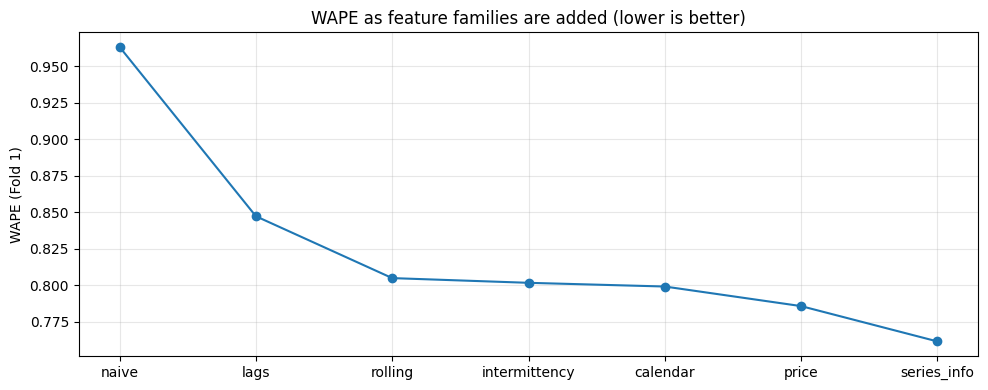

In [12]:
ablation = []
if RUN_ABLATION:
    stage_order = ["lags", "rolling", "intermittency", "calendar", "price", "series_info"]
    cols_so_far = []
    prev = naive_wape
    for g in stage_order:
        cols_so_far = cols_so_far + groups[g]
        t0 = time.time()
        _, pred = fit_predict(cols_so_far)
        w = wape(y, pred)
        mae = float(np.abs(y - pred).mean())
        ablation.append({"added_family": g, "n_features": len(cols_so_far), "WAPE": w, "MAE": mae,
                         "change_vs_prev": w - prev, "seconds": round(time.time() - t0, 1)})
        print(f"+ {g:14s} | features={len(cols_so_far):2d} | WAPE={w:.4f} | change={w-prev:+.4f} | {time.time()-t0:.0f}s")
        prev = w

    abl_df = pd.DataFrame(ablation)
    display(abl_df)

    fig, ax = plt.subplots(figsize=(10, 4))
    labels = ["naive"] + abl_df["added_family"].tolist()
    vals   = [naive_wape] + abl_df["WAPE"].tolist()
    ax.plot(labels, vals, marker="o")
    ax.set_title("WAPE as feature families are added (lower is better)")
    ax.set_ylabel("WAPE (Fold 1)")
    plt.tight_layout(); plt.show()

**Reading the result.** A negative `change_vs_prev` means the family reduced the error. A change close to zero means it did not help on this fold, and very large single-step improvements would deserve a leakage check.

---
## 9. Feature importance and final checks

Gain-based importance shows which features the model used most. Red flags:
- one feature with 90%+ of the importance (possible leakage),
- an identifier-like feature at the top (the model may be memorising series),
- an obviously relevant feature (for example `lag_28` or `dow`) at the bottom (possible bug).

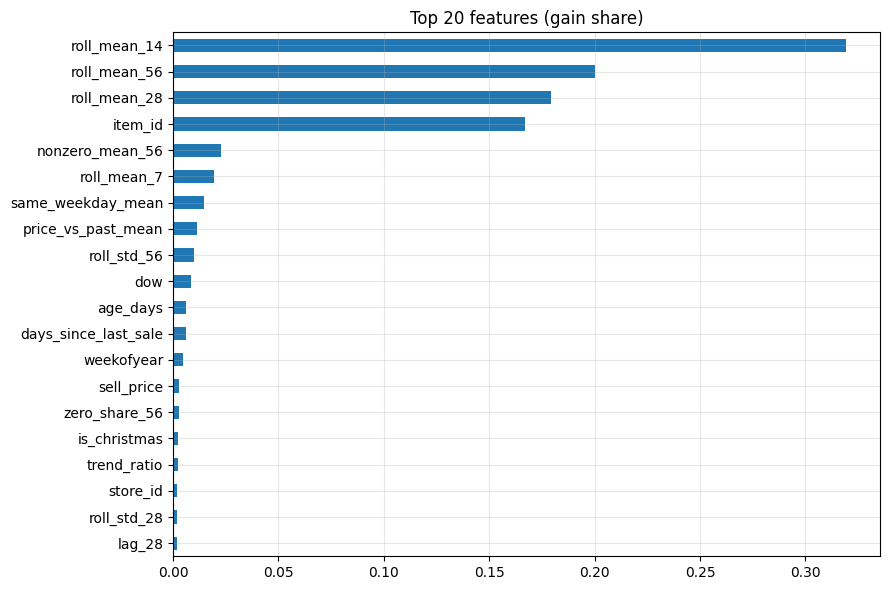

roll_mean_14         0.3194
roll_mean_56         0.2000
roll_mean_28         0.1791
item_id              0.1670
nonzero_mean_56      0.0227
roll_mean_7          0.0194
same_weekday_mean    0.0148
price_vs_past_mean   0.0112
roll_std_56          0.0098
dow                  0.0086

Top-1 feature share: 31.9%

WAPE by volume tier:


,rows,WAPE_naive,WAPE_lgbm
tier,,,
low,9324,1.3441,1.2487
mid,9324,1.1384,0.9637
high,9324,0.8635,0.6409


In [13]:
if RUN_ABLATION:
    all_cols = [c for g in ["lags", "rolling", "intermittency", "calendar", "price", "series_info"] for c in groups[g]]
    model, pred_full = fit_predict(all_cols)

    imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=all_cols)
    imp = (imp / imp.sum()).sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(9, 6))
    imp.head(20)[::-1].plot.barh(ax=ax)
    ax.set_title("Top 20 features (gain share)")
    plt.tight_layout(); plt.show()
    print(imp.head(10).round(4).to_string())
    print(f"\nTop-1 feature share: {imp.iloc[0]:.1%}")

    # WAPE by volume tier (first look at the error analysis)
    seg = pd.DataFrame({"tier": va["vol_tier"].to_numpy(), "y": y, "model": pred_full, "naive": naive_pred})
    rows = []
    for tier in ["low", "mid", "high"]:
        g = seg[seg["tier"] == tier]
        rows.append({"tier": tier, "rows": len(g), "WAPE_naive": wape(g["y"], g["naive"]), "WAPE_lgbm": wape(g["y"], g["model"])})
    seg_res = pd.DataFrame(rows).set_index("tier")
    print("\nWAPE by volume tier:")
    display(seg_res)

**Reading the result.** The tier-wise comparison shows how much of the error comes from sparse, low-volume series: even a good model has WAPE above 1 on the low tier, where a single unit of error is large relative to the tiny totals.

---
## 10. Saving the features

Features for the three horizons (7, 14, 28) are saved as separate Parquet files, using float32 and only available rows after the burn-in period. `feature_config.json` stores the feature groups, folds and assumptions so that the setup can be reproduced.

In [14]:
saved = {}
for h in HORIZONS:
    if h == H:
        d_h, g_h = df, groups
    else:
        d_h, g_h = build_features(long, h)
    d_h = model_rows(d_h, h)
    p = OUT / f"features_h{h}.parquet"
    d_h.to_parquet(p, index=False)
    saved[h] = {"file": p.name, "rows": int(len(d_h)), "groups": g_h}
    print(f"h={h:2d} -> {p.name}  rows={len(d_h):,}  size={p.stat().st_size/1e6:.0f} MB")

config = {
    "horizons": HORIZONS, "main_horizon": H, "seed": SEED,
    "categorical_features": CAT_COLS,
    "target": "sales", "metric": "WAPE",
    "folds": [{k: (str(v.date()) if hasattr(v, "date") else v) for k, v in f.items()} for f in folds],
    "feature_groups_by_horizon": {str(h): saved[h]["groups"] for h in HORIZONS},
    "notes": {
        "unavailable_rows": "sales set to NaN before feature computation; rows excluded from training/eval",
        "price_assumption": "sell_price assumed known in advance at forecast origin",
        "excluded_features": ["year (no extrapolation)", "vol_tier (uses full-period info)"],
    },
}
(OUT / "feature_config.json").write_text(json.dumps(config, indent=2))
print("\nSaved:", sorted(p.name for p in OUT.iterdir()))

h= 7 -> features_h7.parquet  rows=1,468,589  size=34 MB
h=14 -> features_h14.parquet  rows=1,465,243  size=34 MB
h=28 -> features_h28.parquet  rows=1,458,418  size=34 MB

Saved: ['feature_config.json', 'features_h14.parquet', 'features_h28.parquet', 'features_h7.parquet']


---
## 11. Findings and decisions (our run)

| # | Observation | Interpretation | Decision |
|---|---|---|---|
| 1 | Leakage test: 18/18 sales-based features pass for h = 7, 14, 28 | features cannot see the future | features are safe to model with |
| 2 | Fold 1 WAPE: seasonal naive 0.963, LightGBM with all families 0.762 | ML improves on the naive baseline | proceed, but compare with stronger baselines (Notebook 3) |
| 3 | Largest gains: lags (-0.116), rolling (-0.042) | same-weekday history and recent level carry most of the signal | keep both |
| 4 | Price family: -0.013, series-info: -0.024; intermittency and calendar: about -0.003 each | price helps despite rare changes; small effects need more folds to confirm | keep all; re-check in Notebook 3 |
| 5 | Top importances: `roll_mean_14` 32%, `roll_mean_56` 20%, `roll_mean_28` 18%, `item_id` 17% | no single dominant feature | no leakage signal; test `item_id` for cold-start (Notebook 3) |
| 6 | WAPE by volume tier (naive -> LightGBM): low 1.344 -> 1.249, mid 1.138 -> 0.964, high 0.864 -> 0.641 | gain grows with volume; low-volume series stay hard | report errors by tier; also evaluate on weekly totals |

---
## Summary of results (machine-readable)

In [15]:
summary = {
    "rows_all": int(len(df)),
    "rows_model_h28": int(len(dfm)),
    "n_features": len(feature_cols),
    "feature_groups": {g: len(c) for g, c in groups.items()},
    "constant_features": const,
    "nan_share_top5": nan_share.head(5).round(4).to_dict(),
    "leakage_test": {f"h{h}": f"{sum(r.values())}/{len(r)} PASS" for h, r in leak_results.items()},
    "leakage_failed": {f"h{h}": [c for c, ok in r.items() if not ok] for h, r in leak_results.items()},
    "folds": [{k: (str(v.date()) if hasattr(v, "date") else v) for k, v in f.items()} for f in folds],
}
if RUN_ABLATION:
    summary["naive_wape_fold1"] = round(naive_wape, 4)
    summary["ablation"] = [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()} for r in ablation]
    summary["top10_importance"] = imp.head(10).round(4).to_dict()
    summary["wape_by_tier"] = seg_res.round(4).to_dict()
print(json.dumps(summary, indent=2, default=str))

{
  "rows_all": 1911087,
  "rows_model_h28": 1458418,
  "n_features": 37,
  "feature_groups": {
    "lags": 4,
    "rolling": 10,
    "intermittency": 4,
    "calendar": 11,
    "price": 3,
    "series_info": 5
  },
  "constant_features": [],
  "nan_share_top5": {
    "nonzero_mean_56": 0.0842,
    "lag_49": 0.0177,
    "lag_42": 0.015,
    "lag_35": 0.0125,
    "days_since_last_sale": 0.0117
  },
  "leakage_test": {
    "h7": "18/18 PASS",
    "h14": "18/18 PASS",
    "h28": "18/18 PASS"
  },
  "leakage_failed": {
    "h7": [],
    "h14": [],
    "h28": []
  },
  "folds": [
    {
      "fold": 1,
      "train_end": "2016-03-27",
      "valid_start": "2016-03-28",
      "valid_end": "2016-04-24"
    },
    {
      "fold": 2,
      "train_end": "2016-02-28",
      "valid_start": "2016-02-29",
      "valid_end": "2016-03-27"
    },
    {
      "fold": 3,
      "train_end": "2016-01-31",
      "valid_start": "2016-02-01",
      "valid_end": "2016-02-28"
    }
  ],
  "naive_wape_fold1": 0.